# 01 — Data Analysis: Human Perception of AI-Generated Avatars

**Goal.** Walk through the path *raw measurements → cleaning → statistics → figures* in a reproducible way (Task 3).

**Data.**
1. `data/raw/test_run.jsonl` — raw measurements (`src/benchmark.py`): runs with `phase = "warmup"` and `phase = "benchmark"`
   at different loads (number of trials per batch). The latency of the `evaluate_batch` function is measured.
2. The human trials file (`dataset.human_trials_path` in `config.yaml`; by default the **pilot trials** `data/sample/sample_logs.csv`).
   There is no real data yet, n is small, and the conclusions are preliminary.

The processing and plotting logic lives in `src/process_data.py` and `src/visualize.py`; the notebook calls it and shows the results.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

# project modules (this notebook lives in notebooks/)
ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))

from common import load_config, resolve
import process_data as pdx
import visualize as viz

SEED = 42
np.random.seed(SEED)  # global seed
cfg = load_config()
assert cfg["experiment"]["random_seed"] == SEED
rng = np.random.default_rng(SEED)  # bootstrap rng, same call order as process_data.py
pd.set_option("display.width", 200, "display.max_columns", 30)
print(f"seed={SEED}, bootstrap B={cfg['stats']['bootstrap_iterations']}, CI={cfg['stats']['ci_level']}%")

seed=42, bootstrap B=2000, CI=95.0%


## 1. Data Ingestion & Warm-up Filtering

We load the raw log, **validate the schema** (required columns, allowed `phase` values) and
**discard the "cold" runs** (`phase == "warmup"`): the first calls include the warm-up of the interpreter,
caches and allocator, so they distort the estimate of steady-state latency (warm-up bias).

In [2]:
raw = pdx.load_benchmark_log()  # raises ValueError on a bad schema
print("Schema is valid. Records in the raw log:", len(raw))
display(raw.groupby("phase").size().rename("n_records").to_frame())
display(raw.head())

Schema is valid. Records in the raw log: 350


,n_records
phase,
benchmark,210
warmup,140


,timestamp_ns,phase,run_id,load_level,batch_latency_us,latency_per_trial_us,n_invalid,error_rate_pct,n_correct,runtime_error
0,2026-10-25 16:48:04.387613606,warmup,0,1,3.352,3.352,0,0,1,False
1,2026-10-25 16:48:04.387629950,warmup,1,1,1.631,1.631,0,0,1,False
2,2026-10-25 16:48:04.387638804,warmup,2,1,0.917,0.917,0,0,1,False
3,2026-10-25 16:48:04.387645271,warmup,3,1,0.503,0.503,0,0,1,False
4,2026-10-25 16:48:04.387650997,warmup,4,1,0.461,0.461,0,0,1,False


In [3]:
# median latency, warm-up vs benchmark (µs)
cold = raw.pivot_table(index="load_level", columns="phase", values="batch_latency_us", aggfunc="median")
cold["warmup / benchmark"] = cold["warmup"] / cold["benchmark"]
display(cold.round(3))
worst = cold["warmup / benchmark"].idxmax()
print(f"Largest cold-start effect at load {worst}: x{cold.loc[worst, 'warmup / benchmark']:.2f}")

phase,benchmark,warmup,warmup / benchmark
load_level,,,
1,0.283,0.344,1.218
2,0.364,0.383,1.054
5,0.806,0.742,0.921
10,1.146,1.160,1.011
20,1.965,1.991,1.013
50,4.267,4.337,1.016
100,11.366,8.169,0.719


Largest cold-start effect at load 1: x1.22


**How to read it.** A `warmup / benchmark` ratio > 1 means the cold runs are slower than the working ones. The effect depends on the
machine and on the run, but filtering is mandatory in any case: the first calls produce the largest spread.

In [4]:
bench = pdx.filter_warmup(raw)
assert set(bench["phase"]) == {"benchmark"}
print(f"Warm-up dropped: {len(raw) - len(bench)} | Kept for analysis: {len(bench)} (requirement: >= 100)")
assert len(bench) >= 100

Warm-up dropped: 140 | Kept for analysis: 210 (requirement: >= 100)


## 2. Statistical Aggregation

### 2.1 Latency of the measurement system

For every load level: Mean±SD, median, p25/p75, **p95, p99** and **95% bootstrap CIs** (percentile method, B=2000)
for p50/p95/p99. Outliers are flagged with the IQR rule (1.5×IQR) but **not deleted**: some of them are real load spikes
(ss7/ss8: tails must not be cut out, it biases the estimates). The share of invalid trials (`error_rate_pct`) is the guardrail metric (threshold 15%).

In [5]:
latency = pdx.aggregate_latency(bench, cfg, rng)
display(latency)

,load_level,n_runs,mean_us,sd_us,p25_us,p50_us,p75_us,p95_us,p99_us,p50_ci95_low_us,p50_ci95_high_us,p95_ci95_low_us,p95_ci95_high_us,p99_ci95_low_us,p99_ci95_high_us,n_iqr_outliers,error_rate_pct,runtime_errors,guardrail_ok
0,1,30,0.292,0.042,0.254,0.283,0.323,0.368,0.368,0.266,0.304,0.336,0.368,0.357,0.368,0,6.667,0,True
1,2,30,0.393,0.073,0.348,0.364,0.414,0.514,0.638,0.350,0.388,0.435,0.678,0.467,0.678,2,3.333,0,True
2,5,30,0.828,0.166,0.687,0.806,0.945,1.138,1.228,0.700,0.894,0.976,1.237,1.022,1.237,0,10.667,0,True
3,10,30,1.159,0.095,1.122,1.146,1.164,1.234,1.512,1.130,1.155,1.174,1.619,1.204,1.619,2,10.667,0,True
4,20,30,2.095,0.459,1.916,1.965,2.013,2.955,3.810,1.926,1.991,2.057,4.098,2.128,4.098,3,8.333,0,True
5,50,30,4.303,0.139,4.241,4.267,4.324,4.442,4.797,4.243,4.310,4.350,4.938,4.381,4.938,2,9.467,0,True
6,100,30,11.683,4.112,10.124,11.366,11.856,12.498,26.714,10.918,11.763,11.995,32.515,12.340,32.515,1,8.467,0,True


In [6]:
assert latency["guardrail_ok"].all(), "Guardrail violated: the share of invalid trials is above the threshold"
print(f"Guardrail TIR <= {cfg['guardrails']['max_allowed_tir_percent']}% is satisfied at all load levels.")
print("Maximum share of invalid trials:", latency["error_rate_pct"].max().round(2), "%")
print("Runtime failures (runtime_error):", int(latency["runtime_errors"].sum()))

Guardrail TIR <= 15.0% is satisfied at all load levels.
Maximum share of invalid trials: 10.67 %
Runtime failures (runtime_error): 0


### 2.2 Anomaly analysis: load spike or environment noise? (ss7)

An outlier is not necessarily an error. Signs of *environment noise / GC / OS scheduler*: a single trial against a stable
rest of the series, no growth of the median, the IQR flag fires. Signs of a *real load effect*: a shift of the whole median
and reproducibility at neighbouring levels. Below are the levels with the highest p99-to-median ratio.

In [7]:
tail = latency.assign(p99_over_p50=latency["p99_us"] / latency["p50_us"])
display(tail.sort_values("p99_over_p50", ascending=False)[["load_level", "p50_us", "p95_us", "p99_us", "p99_over_p50", "n_iqr_outliers"]].head(3))
spike = tail.loc[tail["p99_over_p50"].idxmax()]
print(f"Heaviest tail: load {int(spike.load_level)}, p99/p50 = {spike.p99_over_p50:.1f}, IQR outliers: {int(spike.n_iqr_outliers)}")
print("Outliers are flagged but kept in the data (non-destructive marking).")

,load_level,p50_us,p95_us,p99_us,p99_over_p50,n_iqr_outliers
6,100,11.366,12.498,26.714,2.350343,1
4,20,1.965,2.955,3.810,1.938931,3
1,2,0.364,0.514,0.638,1.752747,2


Heaviest tail: load 100, p99/p50 = 2.4, IQR outliers: 1
Outliers are flagged but kept in the data (non-destructive marking).


### 2.3 Perception metrics (pilot trials)

The positive class is the **AI avatar**. FPR = a real face judged as AI; FNR = an AI face judged as real.
Invalid trials are not silently discarded but counted in TIR (against selection bias).
All CIs are bootstrap over trials. **Note:** n=8 and n=2, so the intervals are very wide, and degenerate for n=2.
For real data use the participant-level analysis (`src/participant_level.py`): trials of one participant are not independent.

In [8]:
trials = pdx.load_human_trials(cfg)
display(trials)
metrics = pdx.aggregate_human(trials, cfg, rng)
display(metrics[["condition", "n_total", "sample_size", "tir_pct", "accuracy_pct", "fpr_pct", "fnr_pct", "d_prime"]])
display(metrics[["condition", "mean_rt_ms", "std_rt_ms", "p25_rt_ms", "median_p50_ms", "p75_rt_ms", "p95_rt_ms", "p99_rt_ms",
                 "mean_rt_ms_ci95_low", "mean_rt_ms_ci95_high"]])

,participant_id,condition,stimulus_id,is_ai,user_choice,response_time_ms,invalid_rt,invalid_focus,invalid_exposure,is_valid,is_correct,is_iqr_outlier
0,P01,3s_limit,img_01.jpg,1,1,1250,False,False,False,True,True,False
1,P01,3s_limit,img_02.jpg,0,0,890,False,False,False,True,True,False
2,P01,3s_limit,img_03.jpg,1,0,1400,False,False,False,True,False,False
3,P01,3s_limit,img_04.jpg,0,1,1100,False,False,False,True,False,False
4,P01,unrestricted,img_05.jpg,1,1,4200,False,False,False,True,True,False
5,P01,unrestricted,img_06.jpg,0,0,3100,False,False,False,True,True,False
6,P02,3s_limit,img_01.jpg,1,1,1350,False,False,False,True,True,False
7,P02,3s_limit,img_02.jpg,0,0,950,False,False,False,True,True,False
8,P02,3s_limit,img_03.jpg,1,1,1120,False,False,False,True,True,False
9,P02,3s_limit,img_04.jpg,0,0,1050,False,False,False,True,True,False


,condition,n_total,sample_size,tir_pct,accuracy_pct,fpr_pct,fnr_pct,d_prime
0,3s_limit,8,8,0.0,75.0,25.0,25.0,1.049
1,unrestricted,2,2,0.0,100.0,0.0,0.0,1.349


,condition,mean_rt_ms,std_rt_ms,p25_rt_ms,median_p50_ms,p75_rt_ms,p95_rt_ms,p99_rt_ms,mean_rt_ms_ci95_low,mean_rt_ms_ci95_high
0,3s_limit,1138.75,182.243,1025.0,1110.0,1275.0,1382.5,1396.5,1018.75,1258.812
1,unrestricted,3650.00,777.817,3375.0,3650.0,3925.0,4145.0,4189.0,3100.00,4200.000


In [9]:
tests = pdx.run_statistical_tests(trials)
display(tests)

,test,comparison,n_a,n_b,statistic,p_value
0,Fisher exact (accuracy),3s_limit vs unrestricted,8,2,NaN,1.0000
1,Mann-Whitney U (response time),3s_limit vs unrestricted,8,2,0.0,0.0444


**Interpreting the tests.** With n=8 vs n=2 the power of the tests is negligible. For Mann–Whitney p≈0.044 is the smallest achievable
value with such sample sizes, so the results illustrate how the code works and neither confirm nor refute RQ1–RQ2.

In [10]:
# export aggregates (same code path as `python src/process_data.py`)
res = pdx.process_and_aggregate()
pd.testing.assert_frame_equal(res["latency"], latency, check_exact=False, rtol=1e-9)
pd.testing.assert_frame_equal(res["metrics"], metrics, check_exact=False, rtol=1e-9)
print("Saved:", sorted(p.name for p in resolve(cfg["dataset"]["processed_dir"]).glob("*.csv")))
print("The notebook and the CLI script produce identical tables (the seed is fixed).")

[STEP 1] Loading raw JSONL log, validating schema, discarding warm-up runs
         raw=350  warmup dropped=140  kept=210
[STEP 2] Aggregating system latency (p50/p95/p99 + bootstrap 95% CI)


[STEP 3] Aggregating human perception metrics from /home/claude/build/ai-avatar-perception-study/data/sample/sample_logs.csv
[EXPORT] metrics_summary.csv, latency_by_load.csv, statistical_tests.csv -> /home/claude/build/ai-avatar-perception-study/data/processed


Saved: ['latency_by_load.csv', 'metrics_summary.csv', 'statistical_tests.csv']
The notebook and the CLI script produce identical tables (the seed is fixed).


## 3. Visualization & Export

The figures are built by `src/visualize.py` following three rules of scientific visualisation: **(1)** axes with units, a log scale when the spread
covers orders of magnitude; **(2)** a 95% CI on every plot; **(3)** a colour-blind-safe palette + different markers, dashes and hatching (readable in black and white).
Export to `reports/figures/`: `.pdf` (vector) and `.png` (300 DPI).

In [11]:
files = viz.generate_scientific_plots()
print(*[p.name for p in files], sep="\n")

[EXPORT] 8 files (.pdf + .png @300 DPI) -> /home/claude/build/ai-avatar-perception-study/reports/figures
fig1_latency_vs_load.pdf
fig1_latency_vs_load.png
fig2_distribution_boxplot.pdf
fig2_distribution_boxplot.png
fig3_accuracy_comparison.pdf
fig3_accuracy_comparison.png
fig4_error_asymmetry.pdf
fig4_error_asymmetry.png


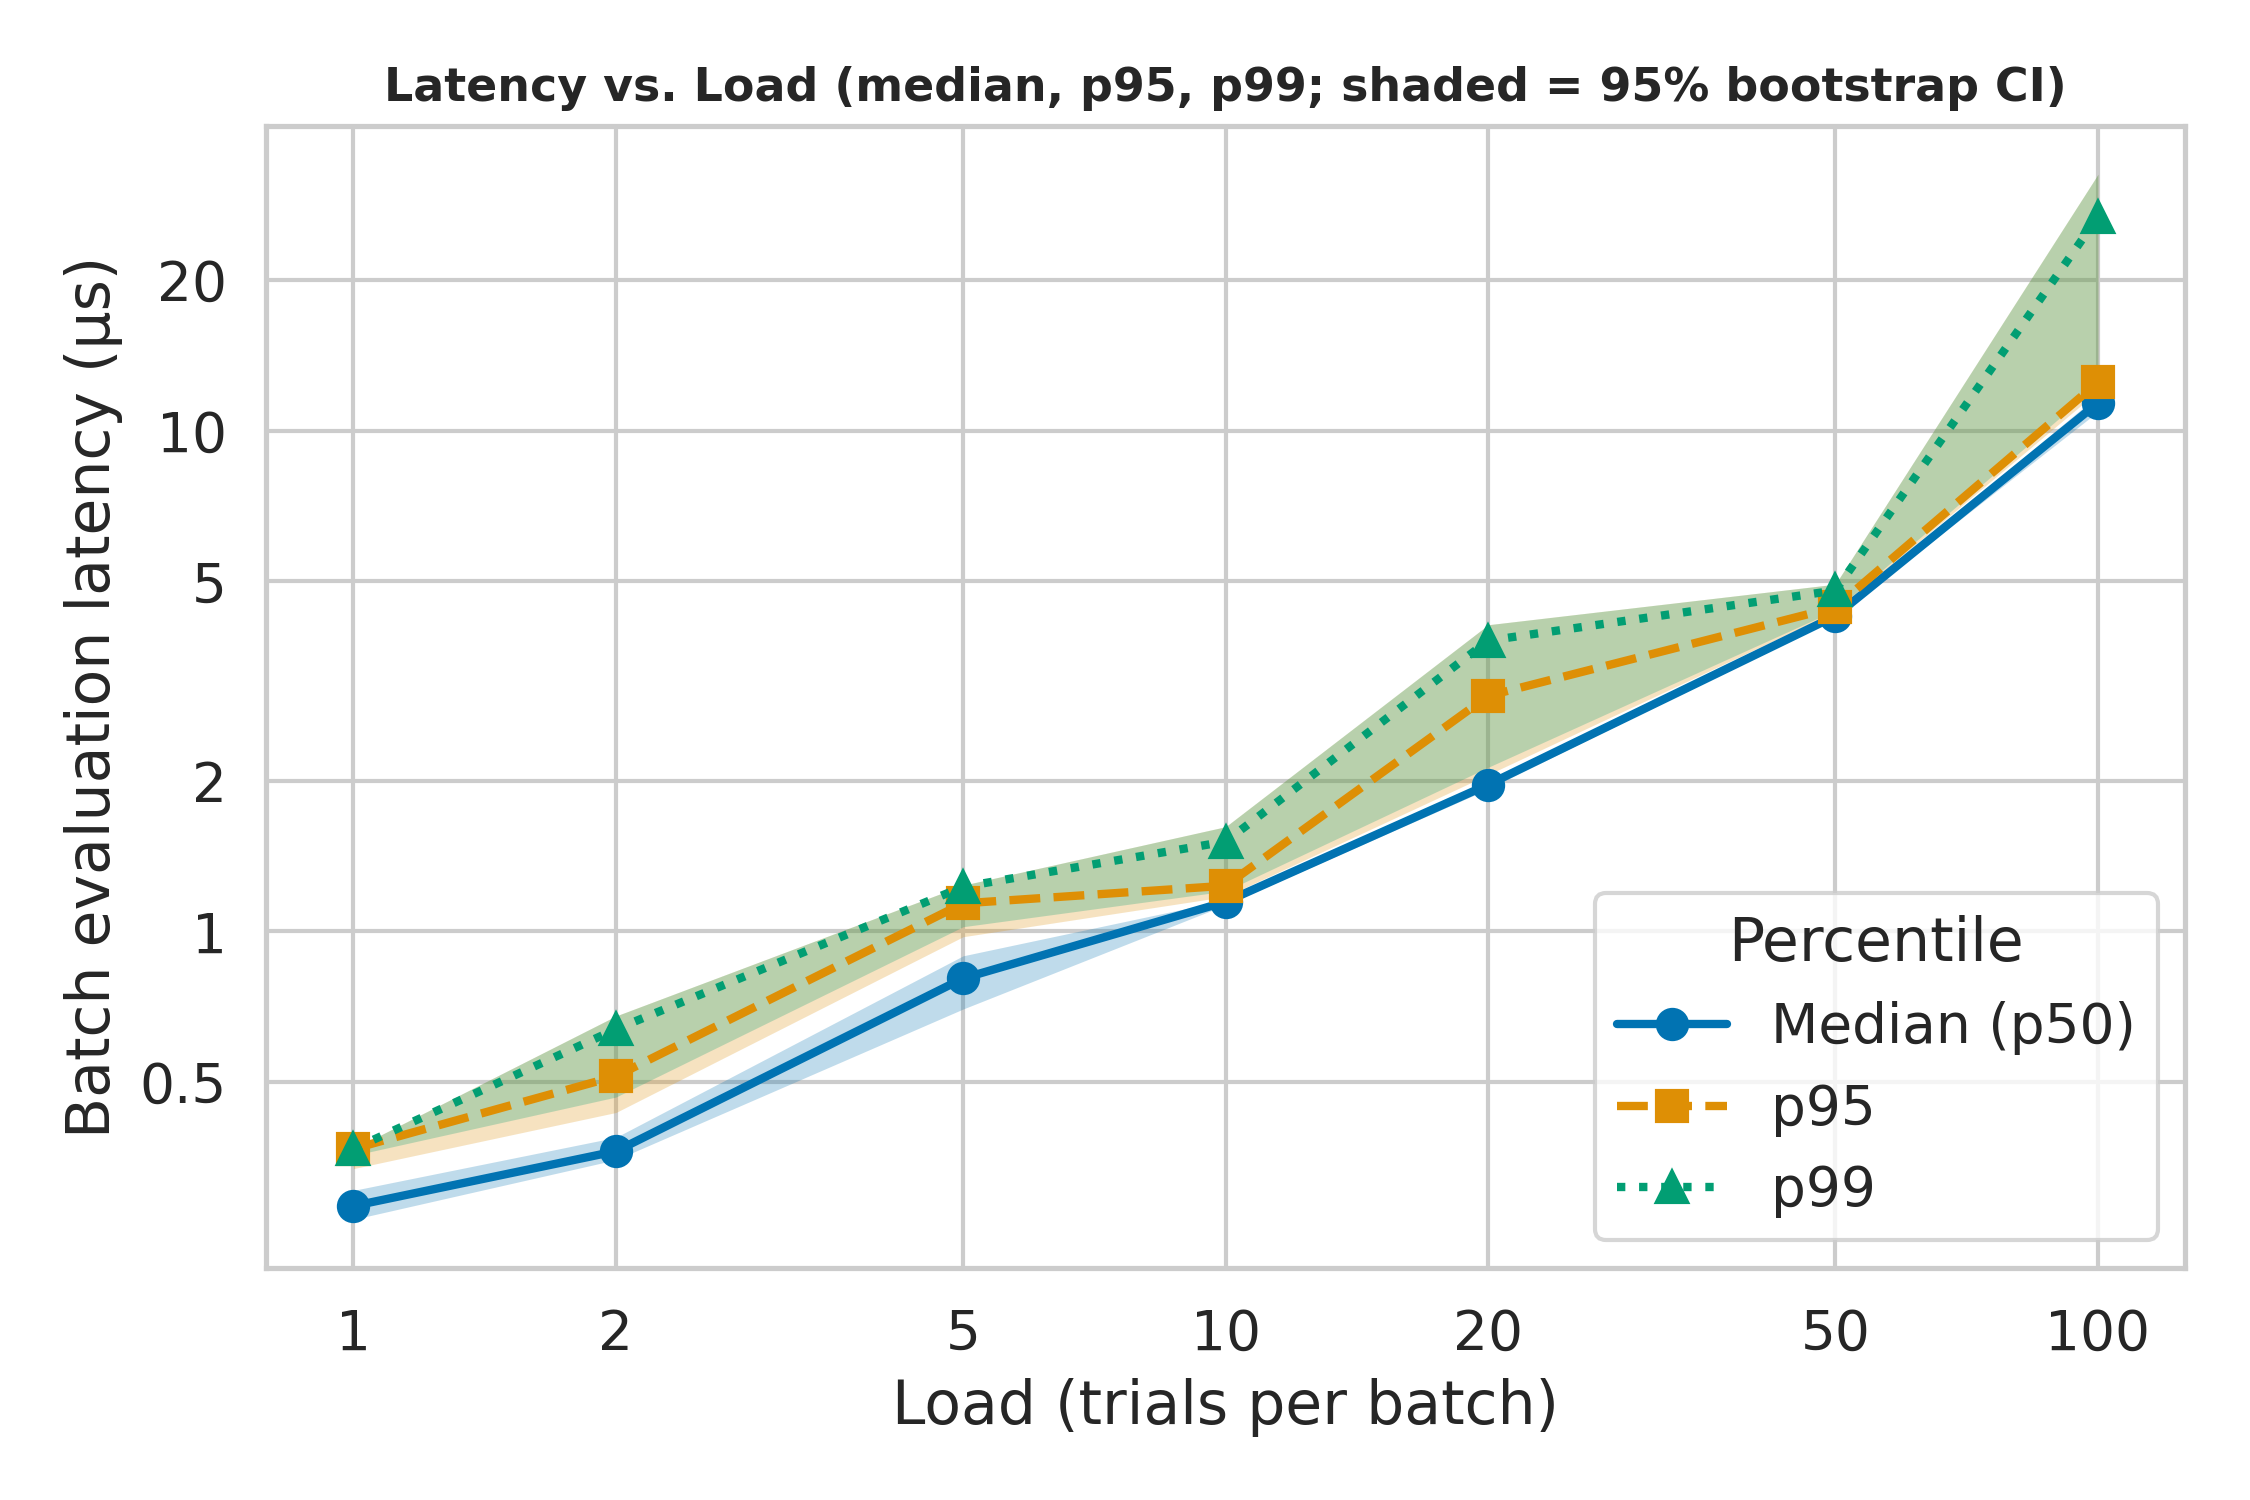

In [12]:
fig_dir = resolve(cfg["dataset"]["figures_dir"])
display(Image(filename=str(fig_dir / "fig1_latency_vs_load.png"), width=620))

**Fig. 1.** Latency as a function of load (log-log). The solid line is the median, the dashed line is p95, the dotted line is p99,
the bands are 95% bootstrap CIs. The median grows roughly linearly with batch size; the p95/p99 tails are wider, and isolated spikes
(see section 2.2) inflate exactly them without affecting the median.

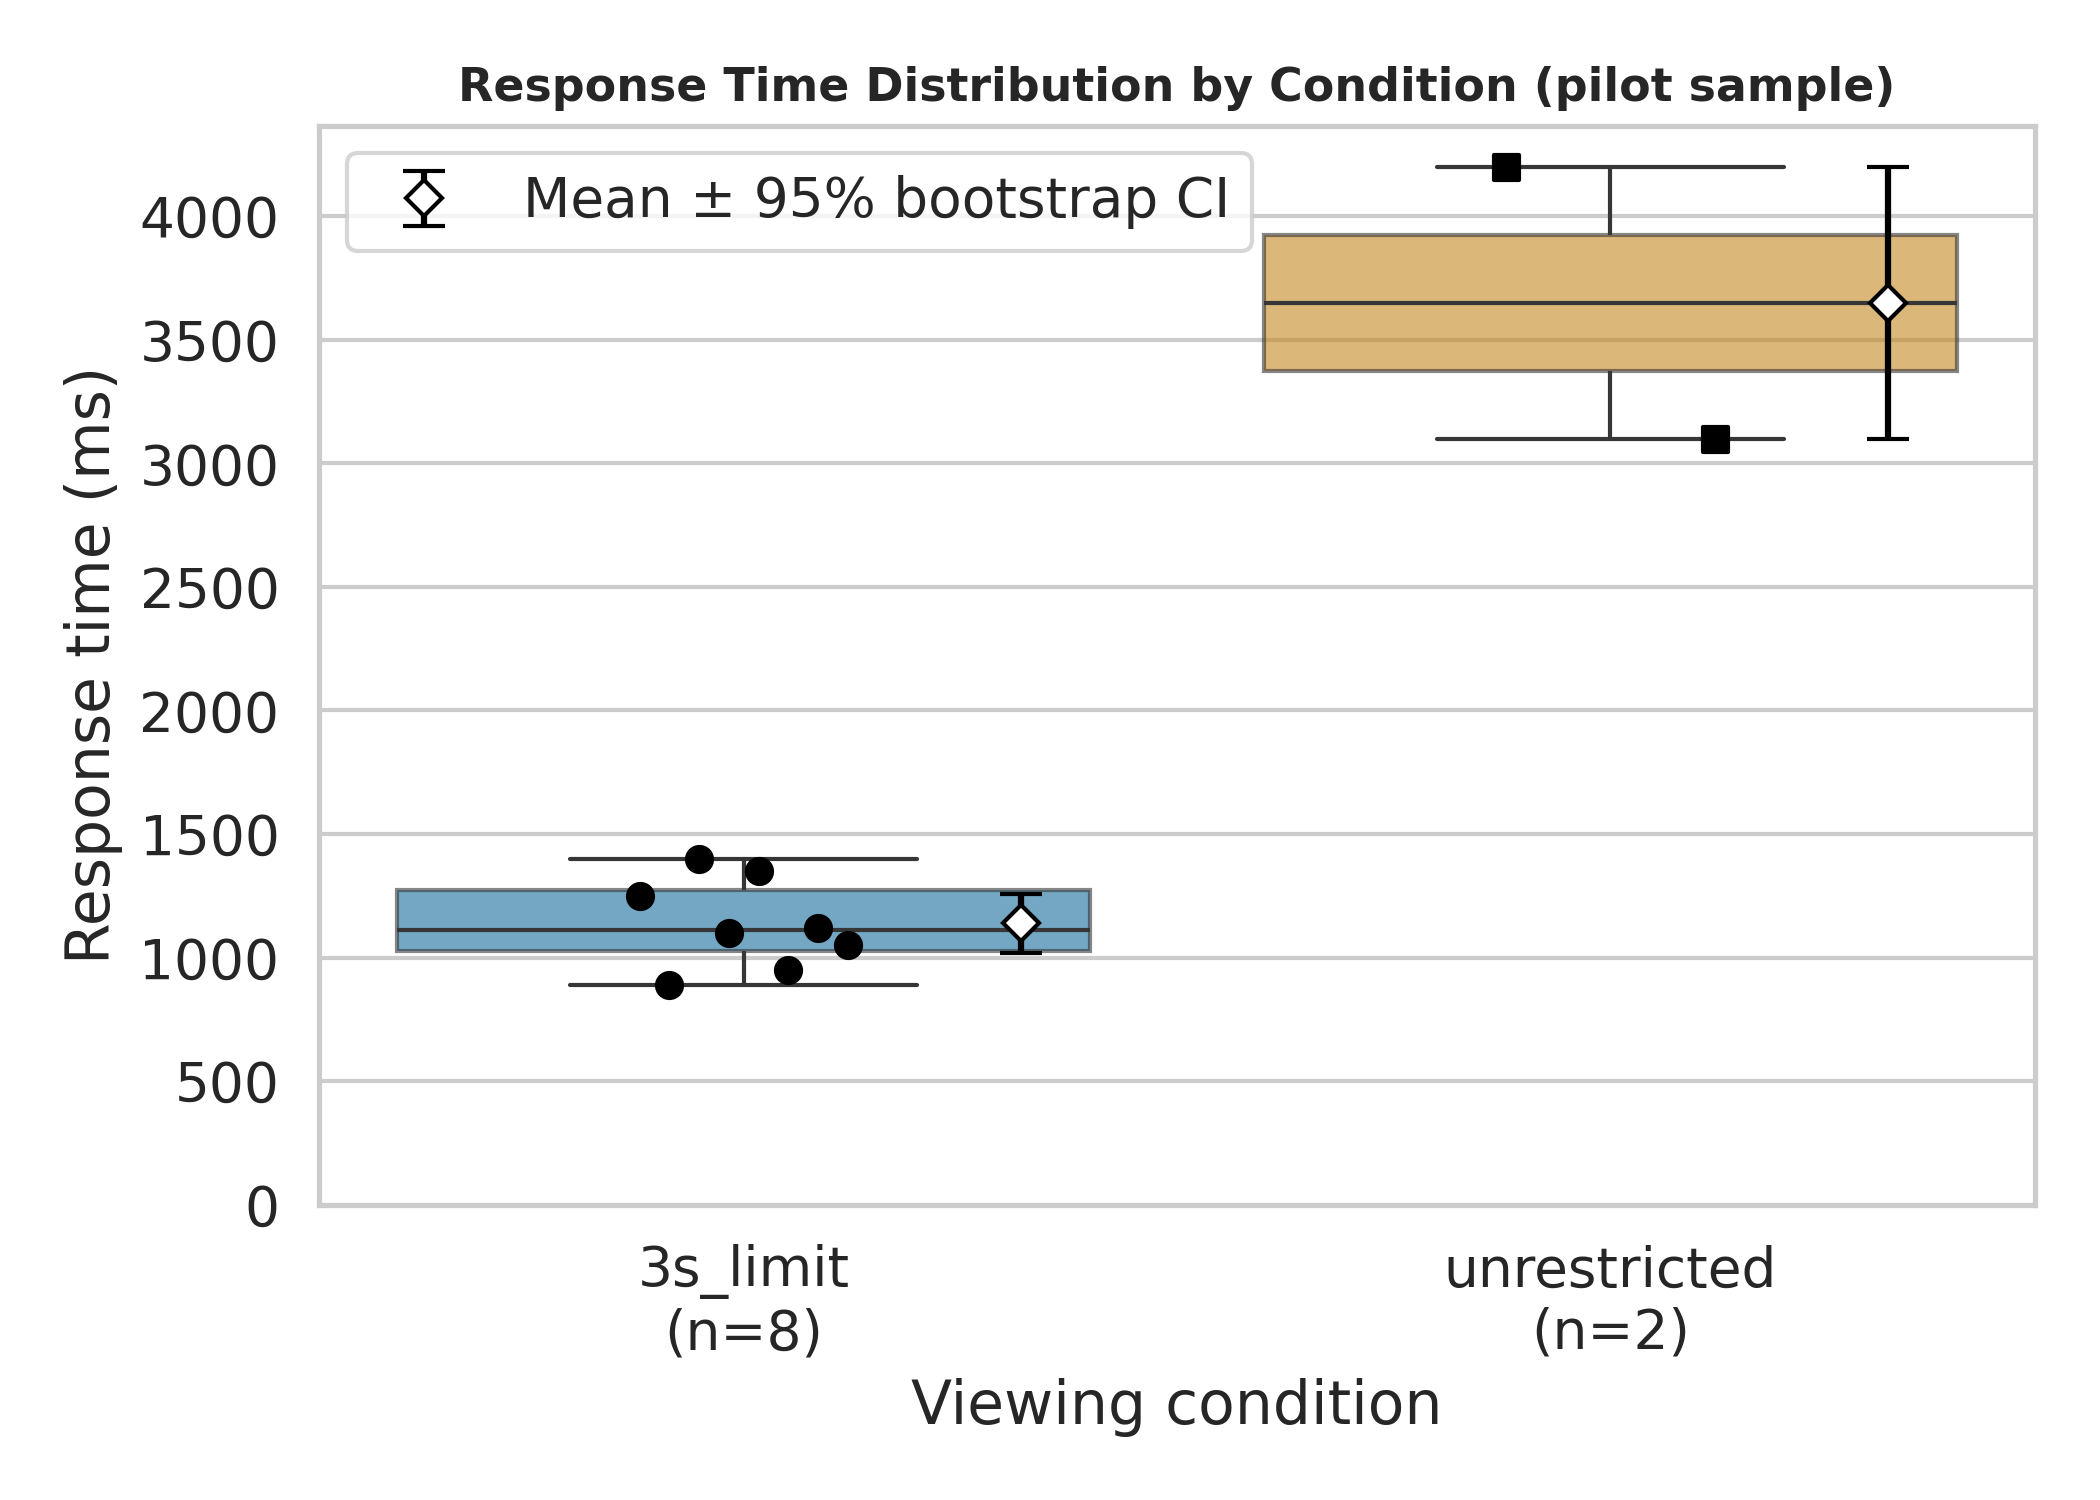

In [13]:
display(Image(filename=str(fig_dir / "fig2_distribution_boxplot.png"), width=520))

**Fig. 2.** In the pilot, response time under the 3 s limit is clearly lower than without a limit, but there are only 2 trials for `unrestricted`,
so the confidence interval practically equals the range.

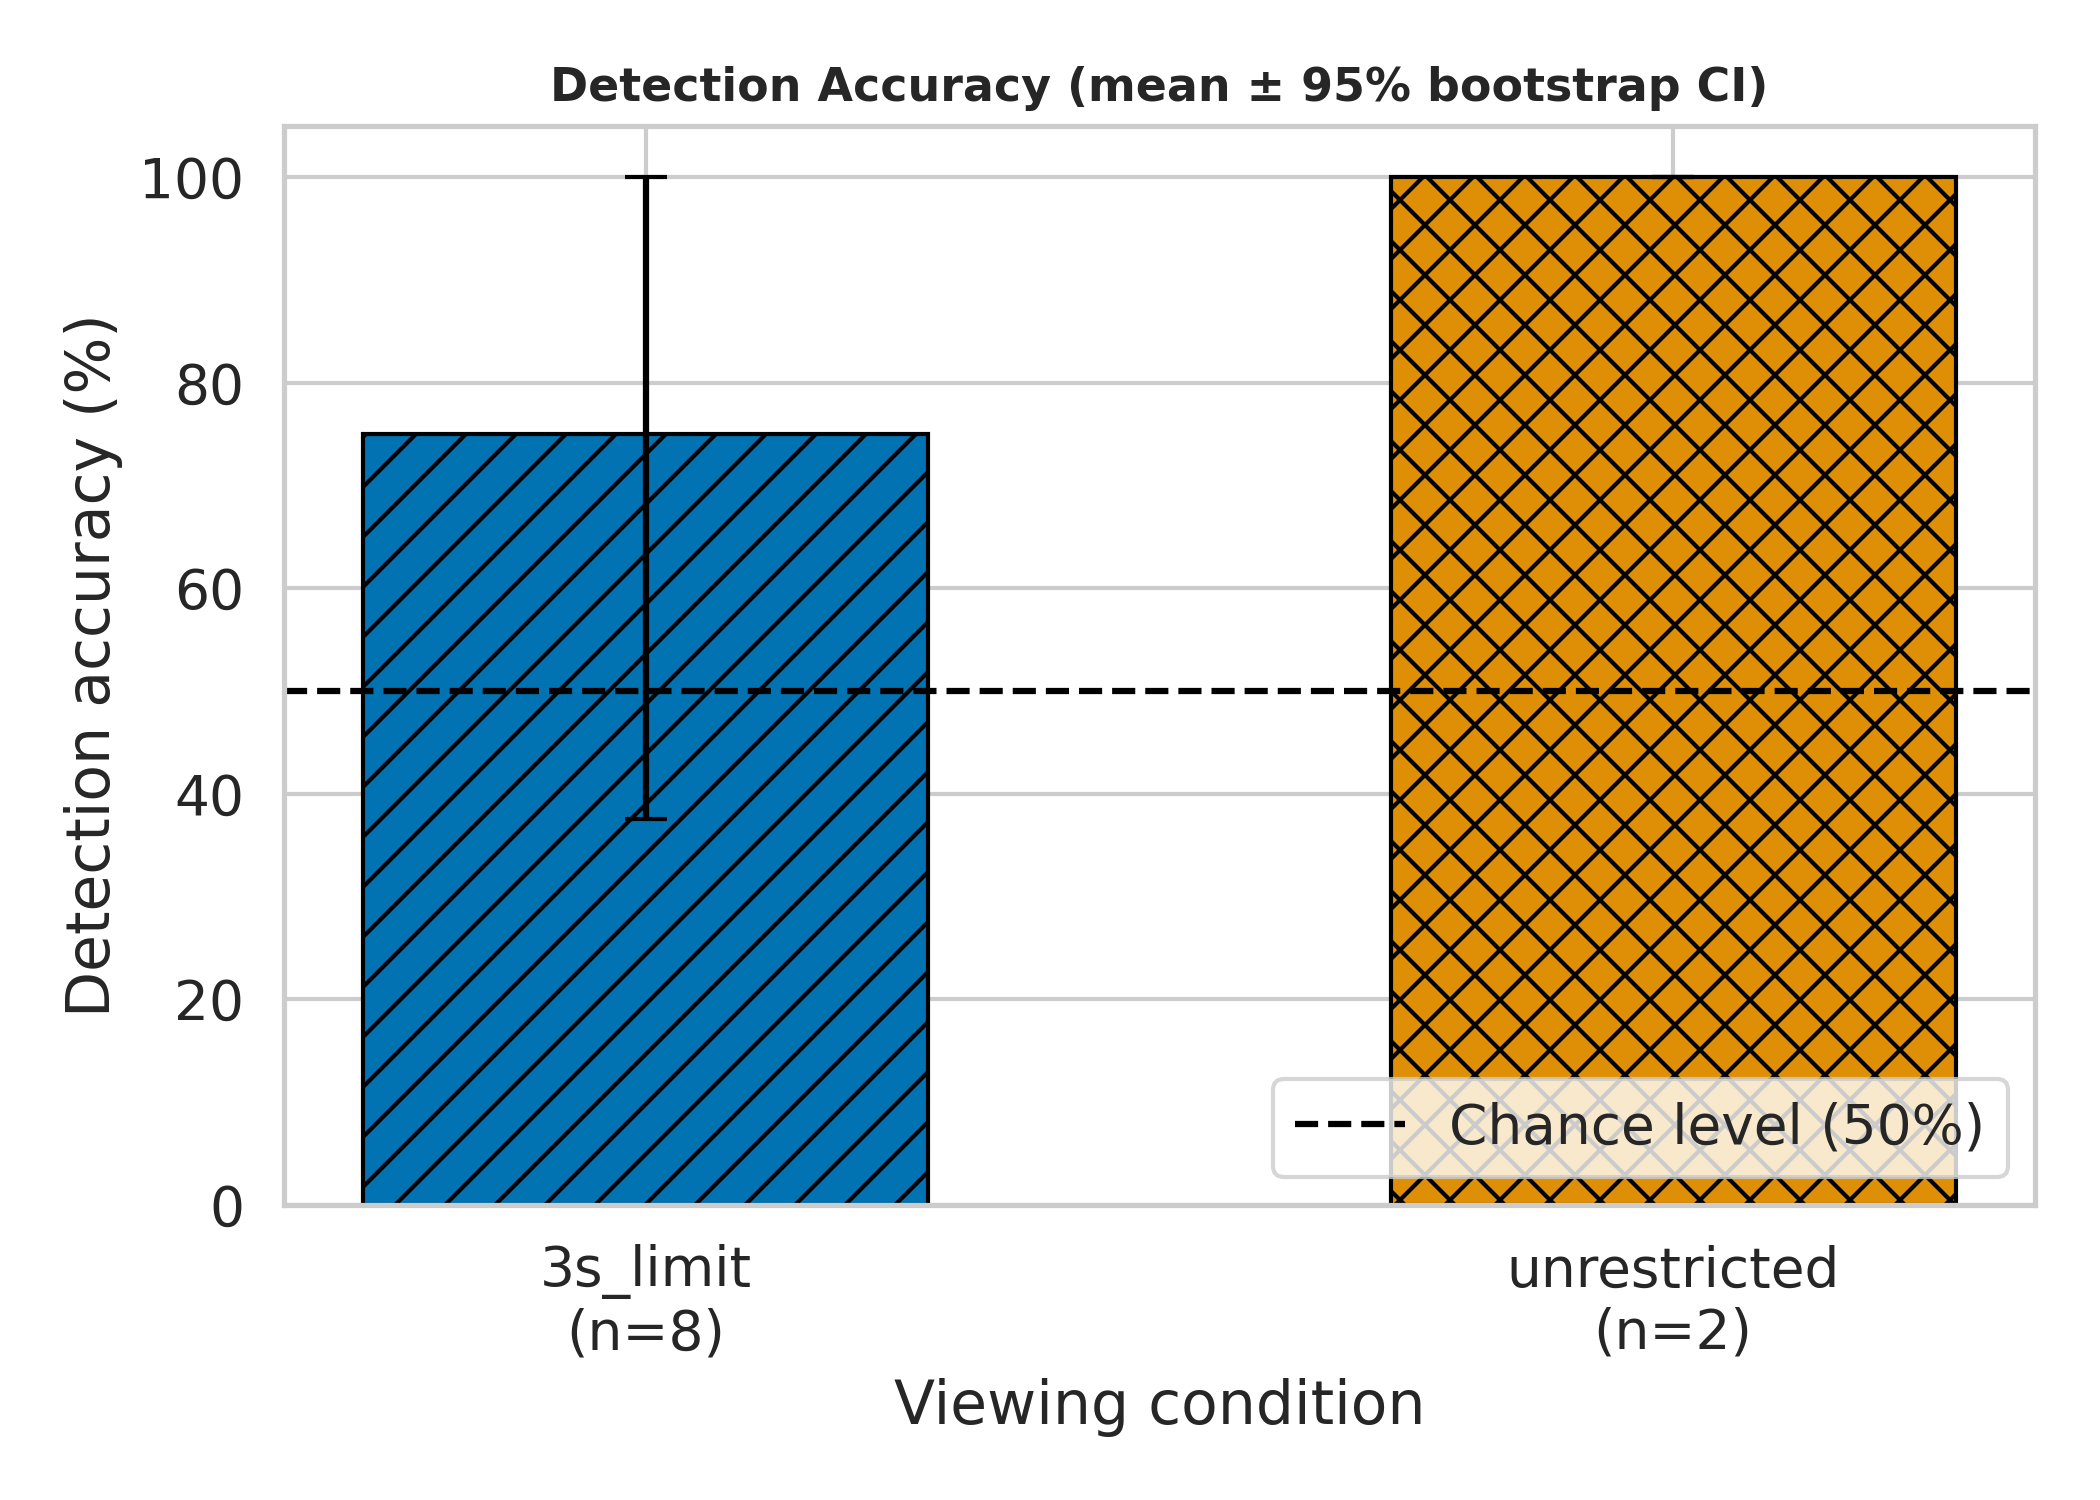

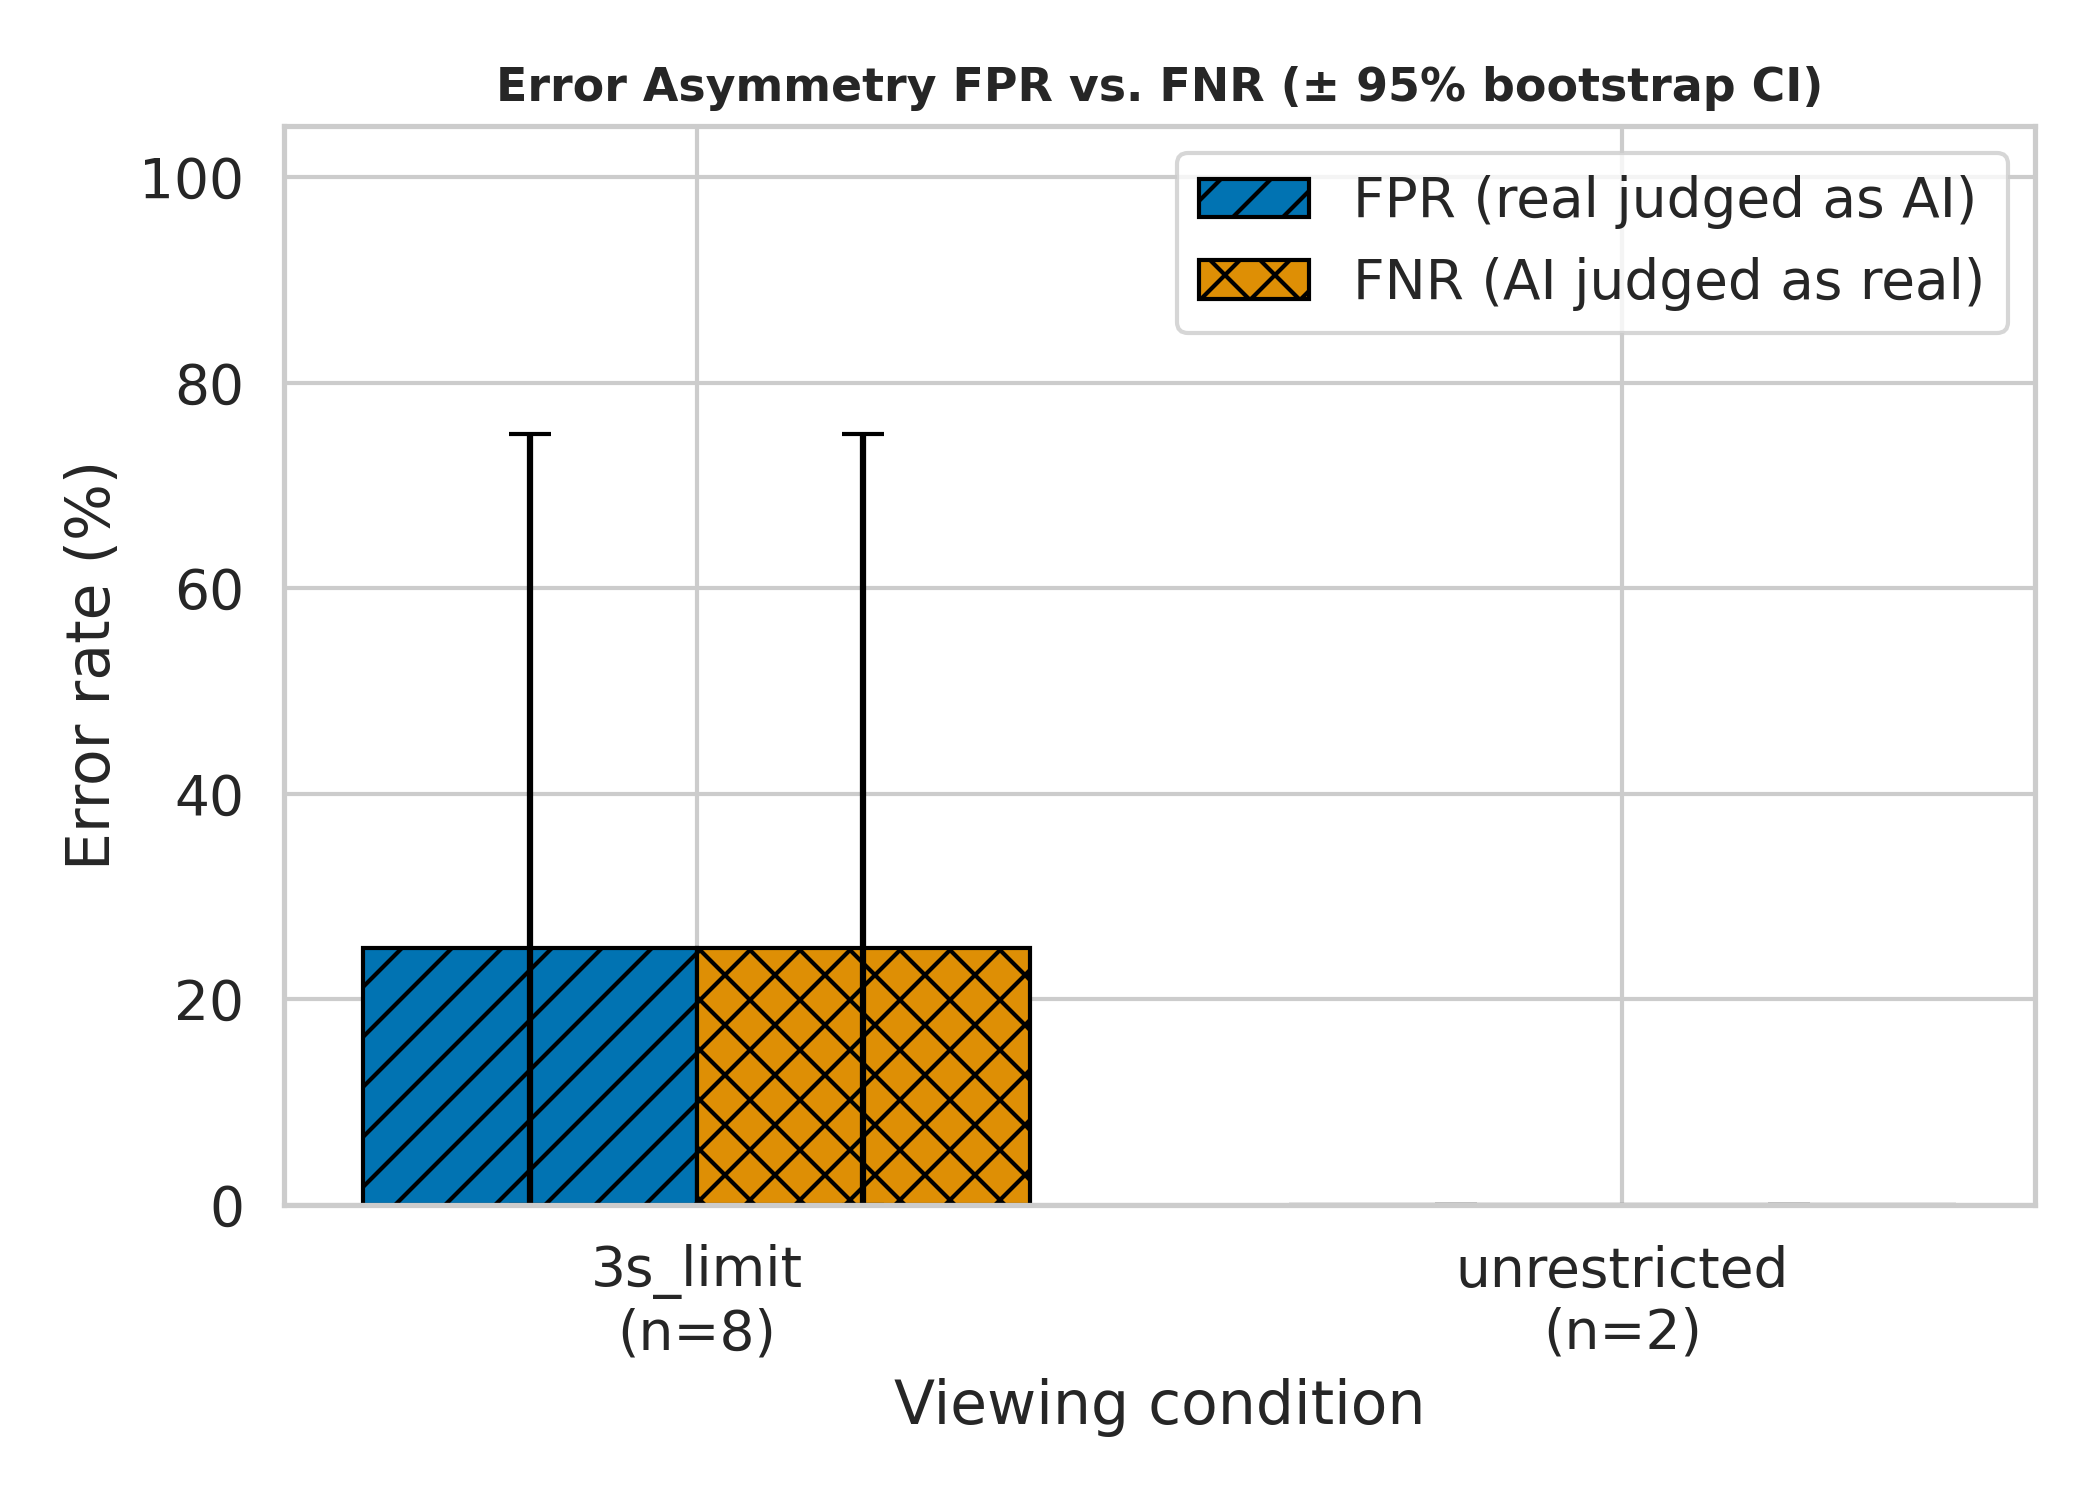

In [14]:
display(Image(filename=str(fig_dir / "fig3_accuracy_comparison.png"), width=520))
display(Image(filename=str(fig_dir / "fig4_error_asymmetry.png"), width=520))

## 4. Plot audit (ss8, step 5)

A checklist of three items. The technical items are verified by code, the others are reflected in `src/visualize.py`.

| # | Check | How it is ensured |
| :-- | :--- | :--- |
| 1 | Axes with units, readable font, correct scale | labels such as `Latency (µs)`, `Response time (ms)`; `font_scale=1.2`; log scale on fig1 (values span orders of magnitude), zero baseline on fig2–fig4 |
| 2 | Spread/uncertainty is shown | 95% CI bands (fig1), Mean±CI diamond (fig2), error bars (fig3–fig4) |
| 3 | Palette for colour-blind readers and black-and-white printing | `sns.color_palette("colorblind")`, different markers, dashes and hatching |

In [15]:
import seaborn as sns
from PIL import Image as PILImage

assert list(viz.PALETTE) == list(sns.color_palette("colorblind")), "the palette must be colorblind"
assert len(set(viz.MARKERS)) >= 3 and len(set(viz.LINESTYLES)) >= 3, "different markers and dashes are required"

rows = []
for name in ["fig1_latency_vs_load", "fig2_distribution_boxplot", "fig3_accuracy_comparison", "fig4_error_asymmetry"]:
    pdf, png = fig_dir / f"{name}.pdf", fig_dir / f"{name}.png"
    is_vector_pdf = pdf.read_bytes()[:4] == b"%PDF"
    dpi = round(PILImage.open(png).info["dpi"][0])
    rows.append({"figure": name, "pdf_vector": is_vector_pdf, "png_dpi": dpi, "dpi_ok(>=300)": dpi >= 300})
audit = pd.DataFrame(rows)
display(audit)
assert audit["pdf_vector"].all() and audit["dpi_ok(>=300)"].all()
print("Export audit passed: all figures are saved as PDF (vector) and PNG >= 300 DPI.")

,figure,pdf_vector,png_dpi,dpi_ok(>=300)
0,fig1_latency_vs_load,True,300,True
1,fig2_distribution_boxplot,True,300,True
2,fig3_accuracy_comparison,True,300,True
3,fig4_error_asymmetry,True,300,True


Export audit passed: all figures are saved as PDF (vector) and PNG >= 300 DPI.


## 5. Conclusions and limitations

* The pipeline works end to end: warm-up is cut off; median, p95, p99, 95% bootstrap CIs and the TIR guardrail are computed.
* The load benchmark (latency of `evaluate_batch`) is based on real measurements; the share of invalid trials stays
  below the 15% threshold (the synthetic "too fast" trial is taken into account).
* The perception metrics are computed on the **pilot sample** (n=8 and n=2): the CIs are wide and the statistical tests are uninformative.
  After real data has been collected, point `dataset.human_trials_path` in `config.yaml` to the new file and re-run the notebook.
* Absolute latency values depend on the machine; the statistical tables for the pilot trials do not.

In [16]:
import platform, matplotlib, scipy
print("Python", platform.python_version(), "|", platform.system(), platform.release())
print("pandas", pd.__version__, "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

Python 3.12.3 | Linux 6.18.44-fc-v180
pandas 3.0.2 | numpy 2.4.4 | scipy 1.17.1 | matplotlib 3.10.8 | seaborn 0.13.2
